## **Árvores Binárias com Costura (*Threaded Binary Tree*)**

É uma estrutura de dados que aproveita os ponteiros nulos de uma árvore binária para armazenar referências a outros nós (sucessor ou antecessor), facilitando o caminhamento pela árvore sem precisar de recursão ou de uma pilha auxiliar. 

(In-order threaded binary tree: left->root->right)

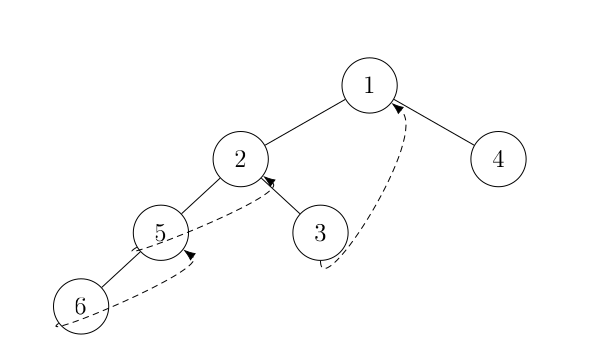

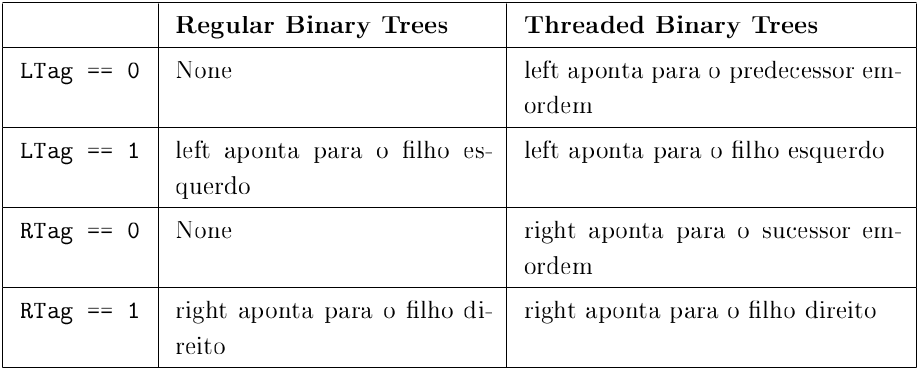

In [25]:
class Node:

    def __init__(self, data = None):
        self.data = data
        self.left = None
        self.right = None

        self.l_tag = False
        self.r_tag = False

In [ ]:
def create_threads(root: Node): # Cria uma árvore com costuras

    nodes = []

    def in_order(root: Node):

        if root is None:
            return 

        in_order(root.left)

        nodes.append(root)

        in_order(root.right)

    in_order(root)

    for i in range(len(nodes)):

        if nodes[i].left is None:
            nodes[i].left = nodes[i-1] if i > 0 else None
            nodes[i].l_tag = True

        if nodes[i].right is None:
            nodes[i].right = nodes[i+1] if i+1 < len(nodes) else None
            nodes[i].r_tag = True

    return root

É comum adicionar um nó *dummy* para facilitar o início e o fim do caminhamento: 

o *dummy* esquerdo aponta para a raiz; 

o *dummy* direito aponta para si mesmo;

e o nó mais a direita da árvore tem costura á direita apontando para o *dummy*.

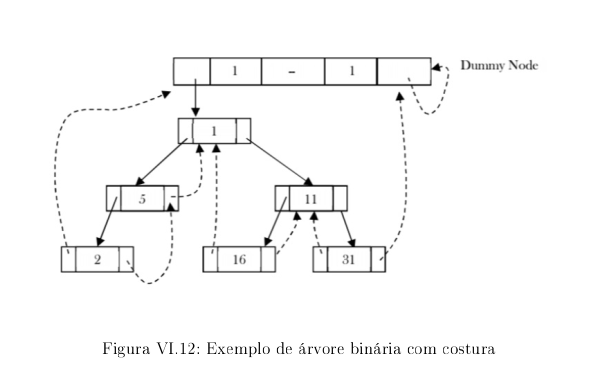

In [27]:
def add_dummy(root: Node):

    if root is None:
        return 

    curr = root

    while not curr.r_tag and curr.right is not None:
        curr = curr.right

    dummy = Node()

    dummy.l_tag = False
    dummy.left = root

    dummy.r_tag = True
    dummy.right = dummy

    curr.r_tag = True
    curr.right = dummy

    curr = root

    while not curr.l_tag and curr.left is not None:
            curr = curr.left

    curr.left = dummy
    curr.l_tag = True

    return dummy

In [28]:
def in_order_traversal(dummy: Node):

    if dummy is None:
        return

    curr = dummy.left

    while not curr.l_tag:
        curr = curr.left

    while curr is not dummy:
        print(curr.data)

        if curr.r_tag:
            curr = curr.right

        else:

            curr = curr.right

            while not curr.l_tag:
                    curr = curr.left

In [29]:
import random as rd

In [31]:
def build_tree(qtd_nodes: int):

    values = rd.sample(range(1,qtd_nodes+1), k=qtd_nodes)

    nodes = [Node(v) for v in values]

    for i in range(qtd_nodes):

        idx_left = 2*i + 1
        idx_right = 2*i + 2

        if idx_left < qtd_nodes:
            nodes[i].left = nodes[idx_left]

        if idx_right < qtd_nodes:
            nodes[i].right= nodes[idx_right]

    root = nodes[0]

    return root


root = build_tree(10)
root = create_threads(root)
dummy = add_dummy(root)
in_order_traversal(dummy)

9
10
8
3
1
6
4
2
7
5
